In [19]:
import pathlib
import sys

from matplotlib import pyplot as plt

# the analysis code lives in grabda_graboa.py next to this notebook
# (run it as a script to regenerate everything: python grabda_graboa.py)
sys.path.insert(0, str(pathlib.Path.cwd()))
import grabda_graboa as gg

plt.rcParams['pdf.fonttype'] = 42

%load_ext autoreload
%autoreload 2
%matplotlib inline

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [20]:
managers = gg.load_session_managers()    # {'DA': ..., 'OA': ...}; folders: see gg.DA_BASEDIR, gg.OA_BASEDIR, gg.DEFAULT_FIGDIR
figdir = gg.DEFAULT_FIGDIR

## Offset variance and vector length, dark vs closed loop

In [21]:
offset_unique = gg.compute_offset_stats(managers)
offset_unique.groupby('group')['fly_id'].nunique()

group
DA    10
OA    11
Name: fly_id, dtype: int64

In [22]:
offset_unique.head()

,fly_id,closed_loop,dark,offset_mean,offset_mag,offset_var,offset_var_logit,group
0,22_11_2024_fly1_grab_DA,1,0,2.167895,0.074331,0.925669,2.521988,DA
1,22_11_2024_fly1_grab_DA,0,1,5.260855,0.072343,0.927657,2.551236,DA
2,22_11_2024_fly2_grab_DA,1,0,2.405895,0.057289,0.942711,2.800651,DA
3,22_11_2024_fly2_grab_DA,0,1,3.768132,0.059192,0.940808,2.765949,DA
4,22_11_2024_fly3_grab_DA,1,0,0.975513,0.063790,0.936210,2.686243,DA


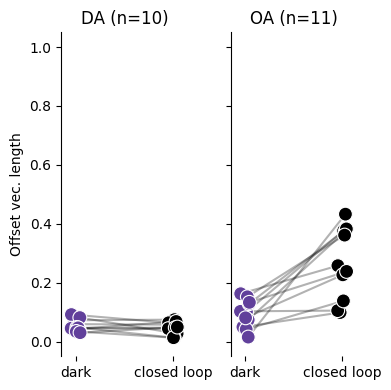

In [23]:
fig = gg.plot_offset_summary(figdir, offset_unique, 'offset_mag', 'Offset vec. length', [-.05, 1.05], 'offset_mag_summary.pdf')


offset_var_mixed_anova


,Source,SS,DF1,DF2,MS,F,p_unc,np2,eps
0,group,17.323413,1,19,17.323413,37.073872,0.000007,0.661161,NaN
1,dark,3.348934,1,19,3.348934,8.980115,0.007416,0.320946,1.0
2,Interaction,6.989752,1,19,6.989752,18.742911,0.000361,0.496594,NaN


offset_var_pairwise_group_first


,Contrast,group,A,B,Paired,Parametric,T,dof,alternative,p_unc,p_corr,p_adjust,BF10,hedges
0,group,-,DA,OA,False,True,6.144274,18.873305,two-sided,0.000007,NaN,NaN,2049.334,2.553986
1,dark,-,0,1,True,True,-2.181415,20.000000,two-sided,0.041259,NaN,NaN,1.589,-0.552190
2,group * dark,DA,0,1,True,True,1.398524,9.000000,two-sided,0.195457,0.195457,holm,0.662,0.510682
3,group * dark,OA,0,1,True,True,-4.393075,10.000000,two-sided,0.001350,0.002699,holm,31.485,-1.773968


offset_var_pairwise_dark_first


,Contrast,dark,A,B,Paired,Parametric,T,dof,alternative,p_unc,p_corr,p_adjust,BF10,hedges
0,dark,-,0,1,True,True,-2.181415,20.000000,two-sided,0.041259,NaN,NaN,1.589,-0.552190
1,group,-,DA,OA,False,True,6.144274,18.873305,two-sided,0.000007,NaN,NaN,2049.334,2.553986
2,dark * group,0,DA,OA,False,True,7.026004,18.951642,two-sided,0.000001,0.000002,holm,1.009e+04,2.939740
3,dark * group,1,DA,OA,False,True,1.820674,15.198921,two-sided,0.088401,0.088401,holm,1.205,0.741673


offset_var_ttest_DA_vs_OA


,condition,t,p,df
0,closed_loop,7.008489,0.000001,19.0
1,dark,1.768185,0.093084,19.0


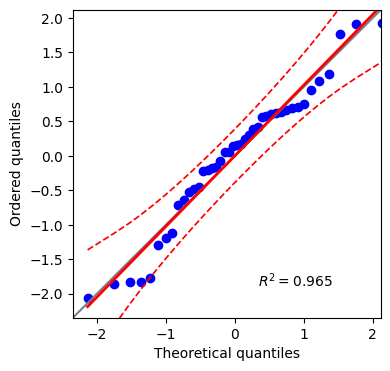

In [24]:
# mixed ANOVA (group x dark/closed loop) and follow-up tests on the logit offset variance
offset_tables = gg.offset_var_tests(figdir, offset_unique)
for name, table in offset_tables.items():
    print(name)
    display(table)

## PV magnitude and whole-EB fluorescence vs rotation speed

In [25]:
grouped, reg_stats = gg.compute_binned_stats(managers)
reg_stats.head()

/home/mplitt/repos/plitt_turnerevans_oa_instructs_hd_plasticity/.venv/lib/python3.11/site-packages/pandas/core/arraylike.py:402: RuntimeWarning: invalid value encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/home/mplitt/repos/plitt_turnerevans_oa_instructs_hd_plasticity/src/el_hd_plasticity/two_photon/stats.py:223: RuntimeWarning: Mean of empty slice
  'F_dig': np.nanmean(np.stack(x['F_dig']), axis=0),
/home/mplitt/repos/plitt_turnerevans_oa_instructs_hd_plasticity/src/el_hd_plasticity/two_photon/stats.py:224: RuntimeWarning: Mean of empty slice
  'rho_dig': np.nanmean(np.stack(x['rho_dig']), axis=0)
/home/mplitt/repos/plitt_turnerevans_oa_instructs_hd_plasticity/.venv/lib/python3.11/site-packages/pandas/core/arraylike.py:402: RuntimeWarning: invalid value encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


,fly_id,closed_loop,rho,log_rho,dh,F,log_F,group
0,02_01_2025_fly1_grab_DA,0,0.145069,-1.930549,0.000000,-0.369282,NaN,DA
1,02_01_2025_fly1_grab_DA,0,0.174707,-1.744648,0.165263,0.152385,-1.881345,DA
2,02_01_2025_fly1_grab_DA,0,0.167021,-1.789635,0.330526,0.411381,-0.888234,DA
3,02_01_2025_fly1_grab_DA,0,0.144995,-1.931054,0.495789,0.504080,-0.685019,DA
4,02_01_2025_fly1_grab_DA,0,0.173194,-1.753345,0.661053,0.512672,-0.668120,DA


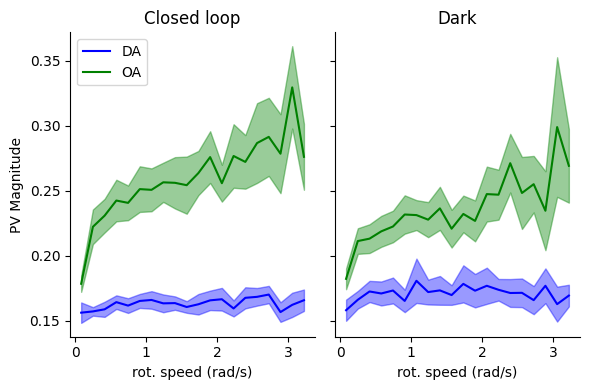

In [26]:
fig = gg.plot_binned_summary(figdir, grouped, 'rho_dig', 'PV Magnitude', 'PV_magnitude_summary.pdf')

In [27]:
rho_tables = gg.binned_stats_tests(figdir, reg_stats, 'log_rho')
for name, table in rho_tables.items():
    print(name)
    display(table) if hasattr(table, 'columns') else print(table)

log_rho_mixed_anova_closed_loop


,Source,SS,DF1,DF2,MS,F,p_unc,p_GG_corr,np2,eps,sphericity,W_spher,p_spher
0,group,21.147373,1,21,21.147373,32.706349,1.121907e-05,NaN,0.608985,NaN,NaN,NaN,NaN
1,dh,1.516824,19,399,0.079833,6.223396,4.887926e-14,0.00016,0.228605,0.269419,False,6.228693e-11,4.390948e-12
2,Interaction,1.090773,19,399,0.057409,4.475348,3.123121e-09,NaN,0.175674,NaN,NaN,NaN,NaN


log_rho_mixed_anova_dark


,Source,SS,DF1,DF2,MS,F,p_unc,p_GG_corr,np2,eps,sphericity,W_spher,p_spher
0,group,9.609790,1,19,9.609790,12.837448,0.001984,NaN,0.403219,NaN,NaN,NaN,NaN
1,dh,0.971983,19,361,0.051157,2.709462,0.000169,0.041363,0.124806,0.222982,False,2.583372e-15,2.859299e-22
2,Interaction,0.780948,19,361,0.041103,2.176940,0.003205,NaN,0.102798,NaN,NaN,NaN,NaN


log_rho_ols_closed_loop
                            OLS Regression Results                            
Dep. Variable:                log_rho   R-squared:                       0.552
Model:                            OLS   Adj. R-squared:                  0.550
Method:                 Least Squares   F-statistic:                     195.5
Date:                Wed, 21 Oct 2026   Prob (F-statistic):           1.52e-82
Time:                        13:53:16   Log-Likelihood:                 78.254
No. Observations:                 479   AIC:                            -148.5
Df Residuals:                     475   BIC:                            -131.8
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept     

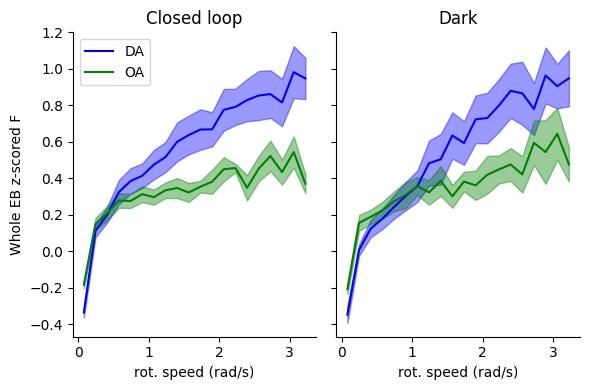

In [28]:
fig = gg.plot_binned_summary(figdir, grouped, 'F_dig', 'Whole EB z-scored F', 'F_summary.pdf')

In [29]:
F_tables = gg.binned_stats_tests(figdir, reg_stats, 'log_F')
for name, table in F_tables.items():
    print(name)
    display(table) if hasattr(table, 'columns') else print(table)

/home/mplitt/repos/plitt_turnerevans_oa_instructs_hd_plasticity/.venv/lib/python3.11/site-packages/scipy/stats/_continuous_distns.py:481: RuntimeWarning: Mean of empty slice
  loc = data.mean()
/home/mplitt/repos/plitt_turnerevans_oa_instructs_hd_plasticity/.venv/lib/python3.11/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/home/mplitt/repos/plitt_turnerevans_oa_instructs_hd_plasticity/.venv/lib/python3.11/site-packages/scipy/stats/_continuous_distns.py:486: RuntimeWarning: Mean of empty slice
  scale = np.sqrt(((data - loc)**2).mean())
/home/mplitt/repos/plitt_turnerevans_oa_instructs_hd_plasticity/.venv/lib/python3.11/site-packages/pingouin/plotting.py:365: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  slope, intercept, r, _, _ = stats.linregress(theor, observed)


log_F_mixed_anova_closed_loop


,Source,SS,DF1,DF2,MS,F,p_unc,np2,eps
0,group,19.397733,1,15,19.397733,6.454878,2.261332e-02,0.300858,NaN
1,dh,47.631464,18,270,2.646192,23.727898,1.794532e-45,0.612682,0.228334
2,Interaction,4.575339,18,270,0.254186,2.279233,2.593165e-03,0.131906,NaN


log_F_mixed_anova_dark


,Source,SS,DF1,DF2,MS,F,p_unc,np2,eps
0,group,17.638520,1,7,17.638520,4.240031,7.846539e-02,0.377226,NaN
1,dh,31.849797,18,126,1.769433,12.134961,9.178646e-20,0.634177,0.179627
2,Interaction,7.975960,18,126,0.443109,3.038888,1.409753e-04,0.302712,NaN


log_F_ols_closed_loop
                            OLS Regression Results                            
Dep. Variable:                  log_F   R-squared:                       0.312
Model:                            OLS   Adj. R-squared:                  0.307
Method:                 Least Squares   F-statistic:                     66.99
Date:                Wed, 21 Oct 2026   Prob (F-statistic):           9.52e-36
Time:                        13:53:18   Log-Likelihood:                -469.71
No. Observations:                 448   AIC:                             947.4
Df Residuals:                     444   BIC:                             963.8
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept       

## Example sessions

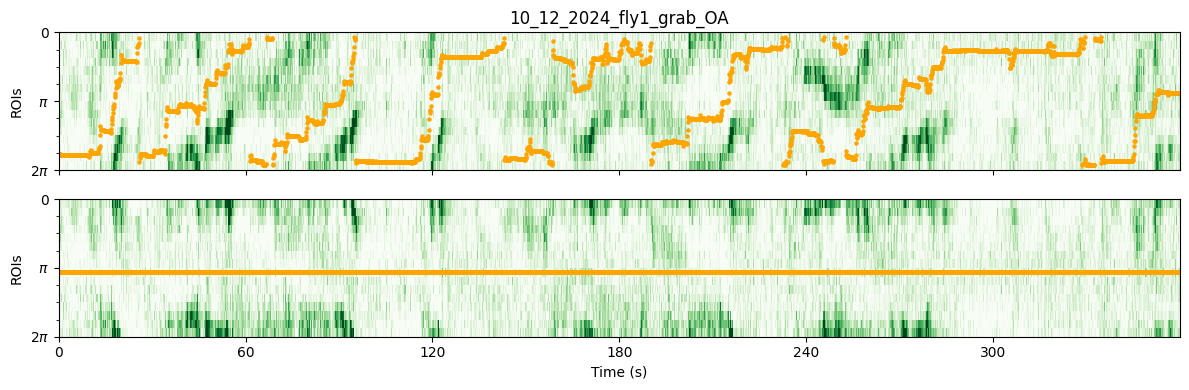

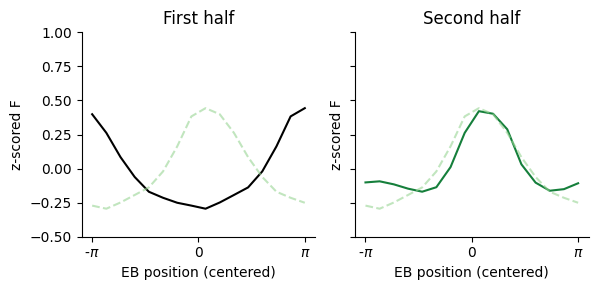

In [30]:
fig_heatmap, fig_mean = gg.plot_example_session(managers['OA'], gg.EXAMPLE_ROWS['OA'], 'Greens', figdir)

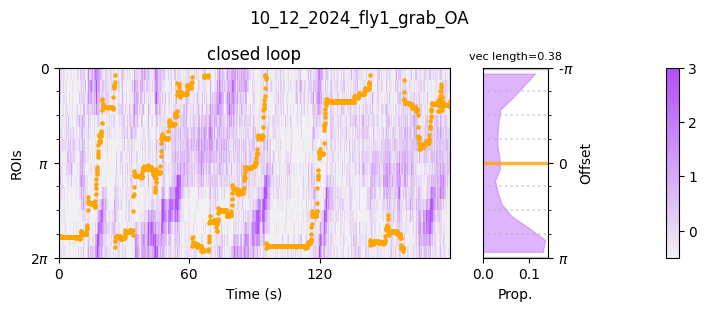

In [31]:
fig = gg.plot_example_heatmap_w_hist(managers['OA'], gg.EXAMPLE_ROWS['OA'], figdir)

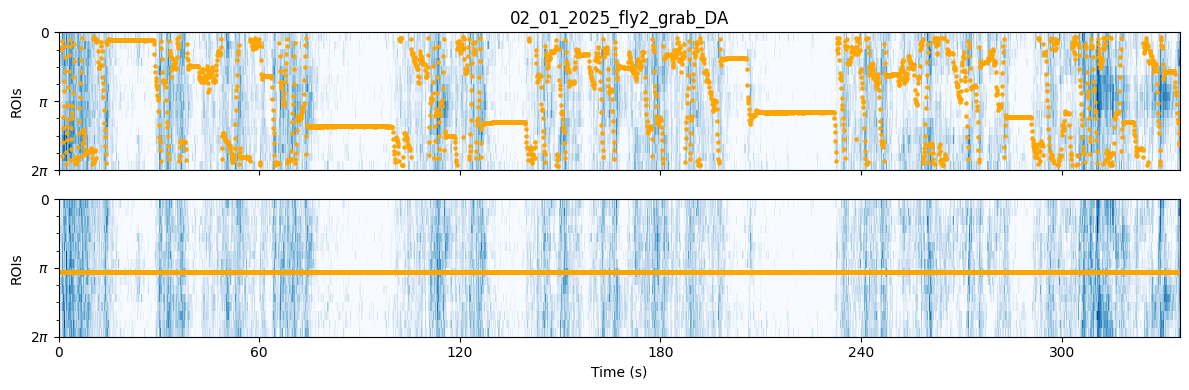

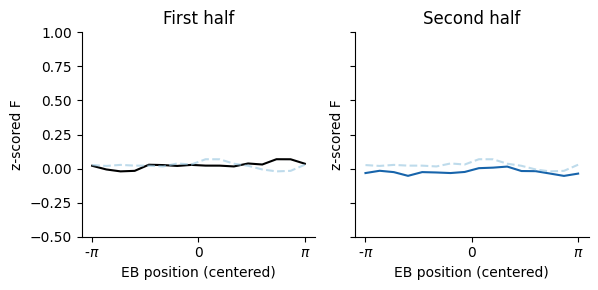

In [32]:
fig_heatmap, fig_mean = gg.plot_example_session(managers['DA'], gg.EXAMPLE_ROWS['DA'], 'Blues', figdir)

## Heading-aligned responses (first vs second half of each closed-loop session)

{'DA': (17, 16), 'OA': (18, 16)}


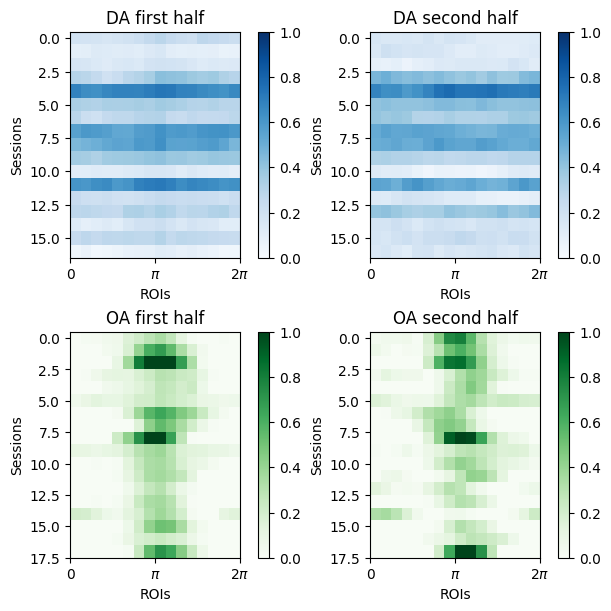

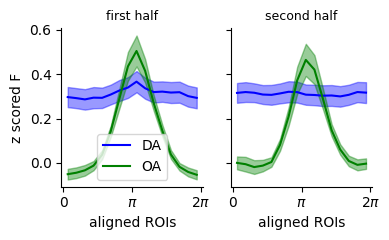

In [33]:
halves = gg.compute_split_halves(managers)
fig_heatmaps, fig_average = gg.plot_split_half_alignment(figdir, halves)
print({group: first.shape for group, (first, _) in halves.items()})

## Figures of every session

In [34]:
for group, sess_manager in managers.items():
    n = gg.plot_session_figures(sess_manager, gg.GROUPS[group][0])
    print(f'{group}: {n} sessions')

DA: 28 sessions
OA: 29 sessions
